In [1]:
from dotenv import load_dotenv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

load_dotenv()

RAW_AQ   = "../data/raw/openaq/"
RAW_TR   = "../data/raw/trends/"
INTERIM  = "../data/interim/"
PROCESSED = "../data/processed/"

CITIES = ["bangkok", "krakow", "melbourne"]
TERMS  = ["air_quality", "air_purifier", "N95_mask"]

print("Ready ✓")

Ready ✓


In [2]:
def clean_aq(city):
    df = pd.read_csv(f"{RAW_AQ}{city}_raw.csv")
    df["date"] = pd.to_datetime(df["date"], utc=True).dt.tz_localize(None)
    
    # Drop physically impossible values
    df = df[(df["pm25"] >= 0) & (df["pm25"] <= 500)]
    
    # Drop low-coverage days (less than 50% of hours reporting)
    df = df[df["percent_complete"] >= 50]
    
    # Resample: average across all sensors per day, then to weekly
    df["week"] = df["date"].dt.to_period("W").dt.start_time
    weekly = (
        df.groupby("week")["pm25"]
        .mean()
        .reset_index()
    )
    weekly.columns = ["week", "pm25_mean"]
    weekly["city"] = city
    
    print(f"{city}: {len(weekly)} weeks | "
          f"PM2.5 {weekly['pm25_mean'].min():.1f}–{weekly['pm25_mean'].max():.1f} µg/m³")
    return weekly

aq_all = pd.concat([clean_aq(c) for c in CITIES], ignore_index=True)

# Save interim
aq_all.to_csv(f"{INTERIM}aq_weekly_all.csv", index=False)
print(f"\n✓ Saved interim AQ weekly → {len(aq_all)} total rows")

bangkok: 154 weeks | PM2.5 12.2–68.0 µg/m³
krakow: 144 weeks | PM2.5 4.8–49.7 µg/m³
melbourne: 102 weeks | PM2.5 3.1–15.5 µg/m³

✓ Saved interim AQ weekly → 400 total rows


In [3]:
def load_trends(city, term):
    df = pd.read_csv(f"{RAW_TR}trends_{city}_{term}.csv")
    df["date"] = pd.to_datetime(df["date"], utc=True).dt.tz_localize(None)
    df = df.rename(columns={"date": "week", "search_index": term})
    df["week"] = df["week"].dt.to_period("W").dt.start_time
    return df.set_index("week")

def load_all_trends(city):
    dfs = [load_trends(city, t) for t in TERMS]
    combined = pd.concat(dfs, axis=1).reset_index()
    combined["city"] = city
    print(f"{city}: {len(combined)} weeks, "
          f"columns: {[c for c in combined.columns if c not in ['week','city']]}")
    return combined

trends_all = pd.concat([load_all_trends(c) for c in CITIES], ignore_index=True)
trends_all.to_csv(f"{INTERIM}trends_weekly_all.csv", index=False)
print(f"\n✓ Saved interim Trends weekly → {len(trends_all)} total rows")

bangkok: 158 weeks, columns: ['air_quality', 'air_purifier', 'N95_mask']
krakow: 158 weeks, columns: ['air_quality', 'air_purifier', 'N95_mask']
melbourne: 158 weeks, columns: ['air_quality', 'air_purifier', 'N95_mask']

✓ Saved interim Trends weekly → 474 total rows


In [4]:
merged = pd.merge(aq_all, trends_all, on=["week", "city"], how="inner")
merged = merged.sort_values(["city", "week"]).reset_index(drop=True)

# Save final processed file
merged.to_csv(f"{PROCESSED}all_cities_combined.csv", index=False)

print(f"✓ Saved → all_cities_combined.csv")
print(f"\nShape: {merged.shape}")
print(f"\nColumns: {list(merged.columns)}")
print(f"\nDate range: {merged['week'].min()} → {merged['week'].max()}")
print(f"\nRows per city:")
print(merged.groupby("city").size())
print(f"\nSample:")
print(merged.head(3))

✓ Saved → all_cities_combined.csv

Shape: (397, 6)

Columns: ['week', 'pm25_mean', 'city', 'air_quality', 'air_purifier', 'N95_mask']

Date range: 2021-12-27 00:00:00 → 2024-12-23 00:00:00

Rows per city:
city
bangkok      153
krakow       143
melbourne    101
dtype: int64

Sample:
        week  pm25_mean     city  air_quality  air_purifier  N95_mask
0 2021-12-27  22.589744  bangkok           12            26        66
1 2022-01-03  39.143258  bangkok           16            29        70
2 2022-01-10  35.985714  bangkok           13            24        61


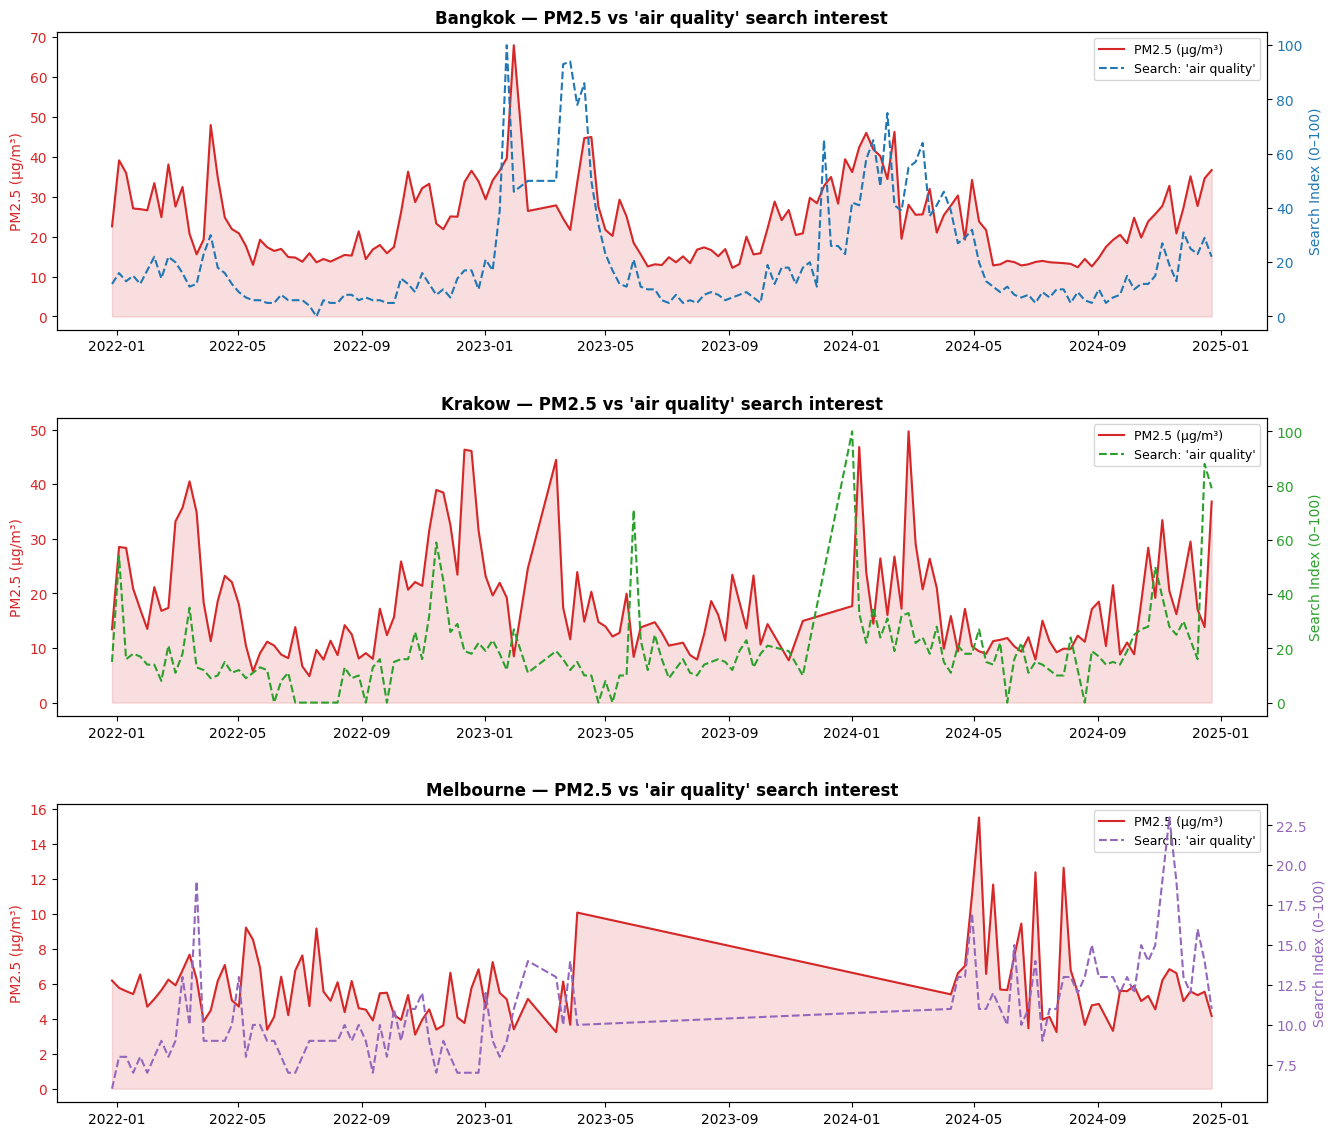

✓ Saved → outputs/figures/timeseries_pm25_vs_search.png


In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

city_colors = {
    "bangkok":   {"pm25": "#d62728", "search": "#1f77b4"},
    "krakow":    {"pm25": "#d62728", "search": "#2ca02c"},
    "melbourne": {"pm25": "#d62728", "search": "#9467bd"}
}

for ax, city in zip(axes, CITIES):
    df = merged[merged["city"] == city].copy()
    df["week"] = pd.to_datetime(df["week"])

    ax2 = ax.twinx()

    # PM2.5 on left axis
    ax.plot(df["week"], df["pm25_mean"], 
            color=city_colors[city]["pm25"], 
            linewidth=1.5, label="PM2.5 (µg/m³)")
    ax.fill_between(df["week"], df["pm25_mean"], 
                    alpha=0.15, color=city_colors[city]["pm25"])

    # Search index on right axis (air_quality term)
    ax2.plot(df["week"], df["air_quality"],
             color=city_colors[city]["search"],
             linewidth=1.5, linestyle="--", label="Search: 'air quality'")

    ax.set_ylabel("PM2.5 (µg/m³)", color=city_colors[city]["pm25"])
    ax2.set_ylabel("Search Index (0–100)", color=city_colors[city]["search"])
    ax.set_title(f"{city.capitalize()} — PM2.5 vs 'air quality' search interest",
                 fontsize=12, fontweight="bold")

    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=9)

    ax.tick_params(axis="y", labelcolor=city_colors[city]["pm25"])
    ax2.tick_params(axis="y", labelcolor=city_colors[city]["search"])
    ax.set_xlabel("")

plt.tight_layout(pad=3.0)
plt.savefig("../outputs/figures/timeseries_pm25_vs_search.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved → outputs/figures/timeseries_pm25_vs_search.png")

In [6]:
from scipy import stats

print("=== PEARSON CORRELATION: PM2.5 vs Search Terms ===\n")

for city in CITIES:
    df = merged[merged["city"] == city].dropna()
    print(f"{city.upper()}")
    for term in TERMS:
        r, p = stats.pearsonr(df["pm25_mean"], df[term])
        sig = "✓ significant" if p < 0.05 else "✗ not significant"
        print(f"  {term:20s} → r={r:+.3f}, p={p:.4f} {sig}")
    print()

=== PEARSON CORRELATION: PM2.5 vs Search Terms ===

BANGKOK
  air_quality          → r=+0.577, p=0.0000 ✓ significant
  air_purifier         → r=+0.522, p=0.0000 ✓ significant
  N95_mask             → r=+0.233, p=0.0038 ✓ significant

KRAKOW
  air_quality          → r=+0.352, p=0.0000 ✓ significant
  air_purifier         → r=+0.500, p=0.0000 ✓ significant
  N95_mask             → r=+nan, p=nan ✗ not significant

MELBOURNE
  air_quality          → r=+0.134, p=0.1823 ✗ not significant
  air_purifier         → r=-0.119, p=0.2379 ✗ not significant
  N95_mask             → r=-0.001, p=0.9928 ✗ not significant



C:\conda_tmp\ipykernel_49856\2906873837.py:9: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = stats.pearsonr(df["pm25_mean"], df[term])


In [7]:
from scipy.signal import correlate

print("=== CROSS-CORRELATION WITH LAGS (weeks) ===\n")
MAX_LAG = 8  # look up to 8 weeks ahead/behind

for city in CITIES:
    df = merged[merged["city"] == city].dropna().copy()
    print(f"{city.upper()}")
    
    for term in TERMS:
        series = df[term]
        # Skip constant series
        if series.std() == 0:
            print(f"  {term:20s} → SKIPPED (constant series)")
            continue
        
        # Normalize both series to zero mean, unit variance
        pm25_norm = (df["pm25_mean"] - df["pm25_mean"].mean()) / df["pm25_mean"].std()
        srch_norm = (series - series.mean()) / series.std()
        
        # Cross-correlate
        cc = correlate(srch_norm, pm25_norm, mode="full")
        lags = np.arange(-(len(pm25_norm)-1), len(pm25_norm))
        
        # Only look at lags -8 to +8
        mask = (lags >= -MAX_LAG) & (lags <= MAX_LAG)
        cc_trim = cc[mask]
        lags_trim = lags[mask]
        
        peak_lag = lags_trim[np.argmax(cc_trim)]
        peak_corr = cc_trim.max() / len(pm25_norm)  # normalize
        
        direction = "search LEADS pollution" if peak_lag < 0 else \
                    "search LAGS pollution" if peak_lag > 0 else \
                    "simultaneous"
        
        print(f"  {term:20s} → peak lag={peak_lag:+d} weeks "
              f"(r={peak_corr:.3f}) — {direction}")
    print()

=== CROSS-CORRELATION WITH LAGS (weeks) ===

BANGKOK
  air_quality          → peak lag=-1 weeks (r=0.641) — search LEADS pollution
  air_purifier         → peak lag=-1 weeks (r=0.581) — search LEADS pollution
  N95_mask             → peak lag=-1 weeks (r=0.330) — search LEADS pollution

KRAKOW
  air_quality          → peak lag=-1 weeks (r=0.514) — search LEADS pollution
  air_purifier         → peak lag=-1 weeks (r=0.593) — search LEADS pollution
  N95_mask             → SKIPPED (constant series)

MELBOURNE
  air_quality          → peak lag=-1 weeks (r=0.170) — search LEADS pollution
  air_purifier         → peak lag=-7 weeks (r=-0.011) — search LEADS pollution
  N95_mask             → peak lag=-8 weeks (r=0.038) — search LEADS pollution



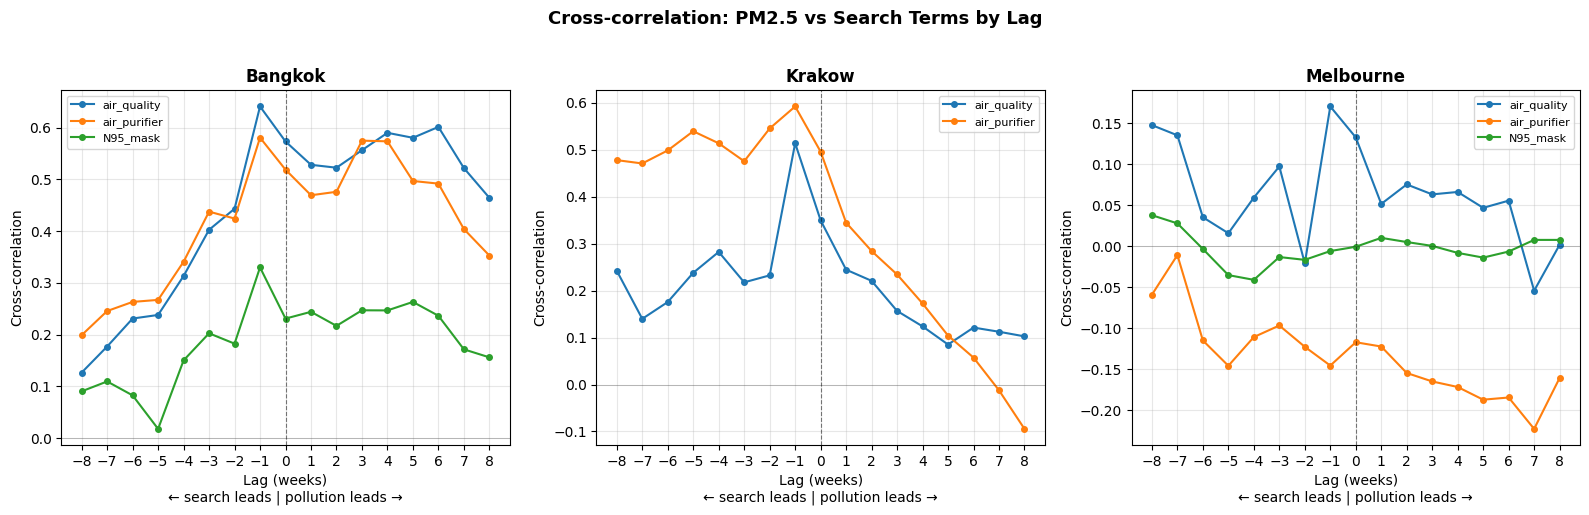

✓ Saved → outputs/figures/crosscorr_lag_plot.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, city in zip(axes, CITIES):
    df = merged[merged["city"] == city].dropna().copy()
    pm25_norm = (df["pm25_mean"] - df["pm25_mean"].mean()) / df["pm25_mean"].std()

    for term, color in zip(TERMS, ["#1f77b4", "#ff7f0e", "#2ca02c"]):
        series = df[term]
        if series.std() == 0:
            continue
        srch_norm = (series - series.mean()) / series.std()
        cc = correlate(srch_norm, pm25_norm, mode="full")
        lags = np.arange(-(len(pm25_norm)-1), len(pm25_norm))
        mask = (lags >= -8) & (lags <= 8)
        cc_norm = cc[mask] / len(pm25_norm)
        ax.plot(lags[mask], cc_norm, marker="o", markersize=4,
                label=term, color=color)

    ax.axvline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
    ax.axhline(0, color="black", linestyle="-", linewidth=0.5, alpha=0.3)
    ax.set_title(f"{city.capitalize()}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Lag (weeks)\n← search leads | pollution leads →")
    ax.set_ylabel("Cross-correlation")
    ax.legend(fontsize=8)
    ax.set_xticks(range(-8, 9))
    ax.grid(alpha=0.3)

plt.suptitle("Cross-correlation: PM2.5 vs Search Terms by Lag",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../outputs/figures/crosscorr_lag_plot.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved → outputs/figures/crosscorr_lag_plot.png")

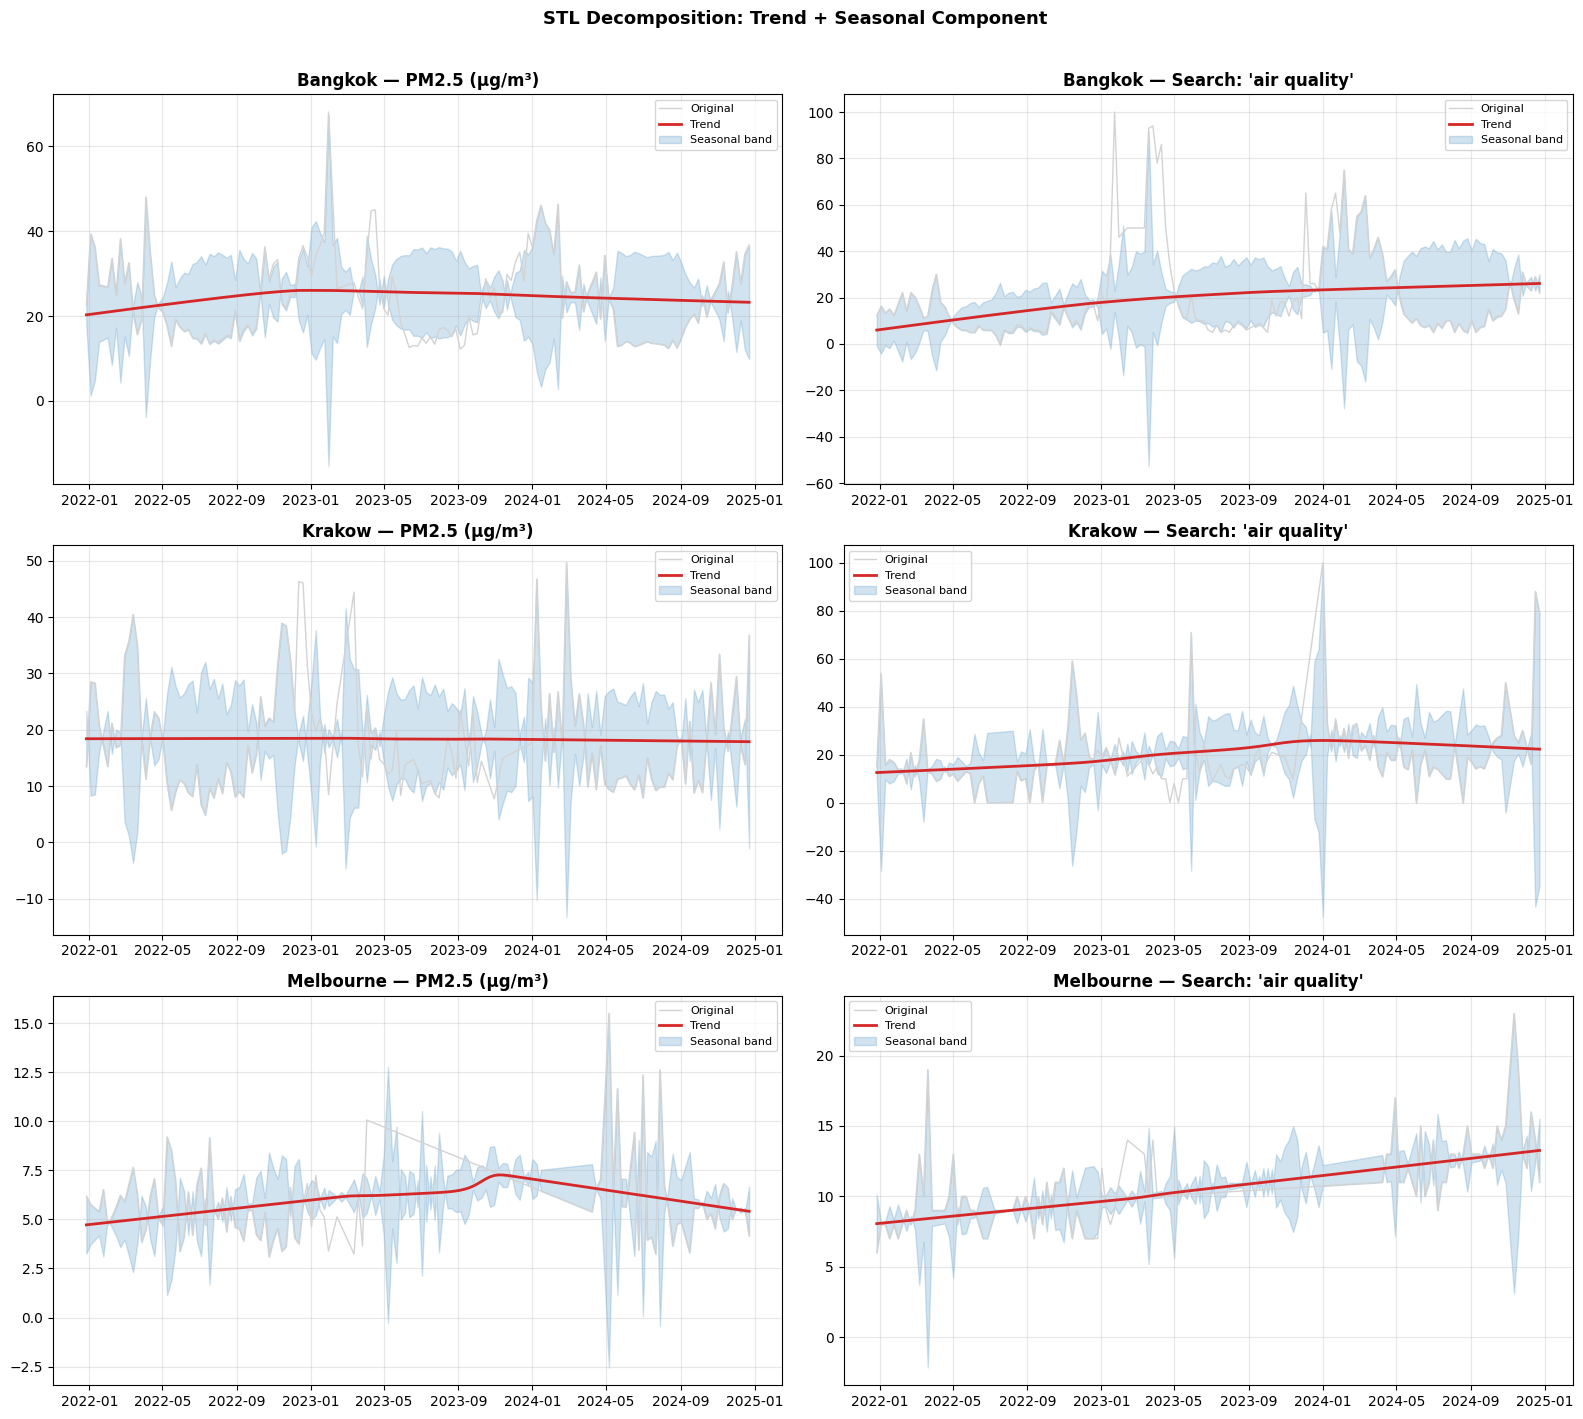

✓ Saved → outputs/figures/stl_decomposition.png


In [9]:
from statsmodels.tsa.seasonal import STL

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

for row, city in enumerate(CITIES):
    df = merged[merged["city"] == city].copy()
    df["week"] = pd.to_datetime(df["week"])
    df = df.set_index("week").asfreq("W-MON")

    for col, (series_col, label) in enumerate([
        ("pm25_mean", "PM2.5 (µg/m³)"),
        ("air_quality", "Search: 'air quality'")
    ]):
        ax = axes[row][col]
        series = df[series_col].interpolate()

        stl = STL(series, period=52, robust=True)
        result = stl.fit()

        ax.plot(df.index, series, color="lightgrey", linewidth=1, label="Original")
        ax.plot(df.index, result.trend, color="#d62728", linewidth=2, label="Trend")
        ax.fill_between(df.index,
                        result.trend - result.seasonal,
                        result.trend + result.seasonal,
                        alpha=0.2, color="#1f77b4", label="Seasonal band")

        ax.set_title(f"{city.capitalize()} — {label}", fontweight="bold")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

plt.suptitle("STL Decomposition: Trend + Seasonal Component",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("../outputs/figures/stl_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved → outputs/figures/stl_decomposition.png")